<a href="https://colab.research.google.com/github/turkomaluco/dio-desafio-githubprimeirorepositorio/blob/main/C%C3%B3pia_de_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
if torch.cuda.is_available():
    print("GPU T4 ativada com sucesso! Pronta para o treino.")
    print("Placa de vídeo:", torch.cuda.get_device_name(0))
else:
    print("ATENÇÃO: A GPU não está ativa. Vá em 'Ambiente de execução' > 'Alterar tipo de ambiente' e selecione 'T4 GPU'.")

GPU T4 ativada com sucesso! Pronta para o treino.
Placa de vídeo: Tesla T4


In [ ]:
from google.colab import drive
import os
import zipfile
import shutil

# 1. Conecta o Google Drive
drive.mount('/content/drive')

# 2. Cria a pasta do projeto no Colab
os.makedirs('/content/avaliador_facial', exist_ok=True)
os.chdir('/content/avaliador_facial')

# 3. Copia os arquivos do Google Drive para o Colab
# (Certifique-se de que 'Images.zip', 'All_labels.txt' e 'beauty_rater.py' estão na raiz do seu Google Drive)
caminho_drive = '/content/drive/MyDrive' # Altere se salvou dentro de alguma pasta específica

arquivos_necessarios = ['Images.zip', 'All_labels.txt', 'beauty_rater.py']
for arquivo in arquivos_necessarios:
    origem = os.path.join(caminho_drive, arquivo)
    if os.path.exists(origem):
        shutil.copy(origem, f'/content/avaliador_facial/{arquivo}')
        print(f"✔️ Copiado com sucesso: {arquivo}")
    else:
        print(f"❌ ATENÇÃO: O arquivo '{arquivo}' não foi encontrado em '{caminho_drive}'. Verifique se ele está lá!")

# 4. Extrai as imagens automaticamente se o zip foi encontrado
if os.path.exists('Images.zip'):
    print("Extraindo imagens...")
    with zipfile.ZipFile('Images.zip', 'r') as zip_ref:
        zip_ref.extractall('/content/avaliador_facial')
    print("Dataset extraído e pronto para uso!")


Mounted at /content/drive
❌ ATENÇÃO: O arquivo 'Images.zip' não foi encontrado em '/content/drive/MyDrive'. Verifique se ele está lá!
❌ ATENÇÃO: O arquivo 'All_labels.txt' não foi encontrado em '/content/drive/MyDrive'. Verifique se ele está lá!
❌ ATENÇÃO: O arquivo 'beauty_rater.py' não foi encontrado em '/content/drive/MyDrive'. Verifique se ele está lá!


In [ ]:
from google.colab import drive
import os
import zipfile
import shutil

# 1. Conecta o Google Drive (se já estiver conectado, ele apenas segue)
drive.mount('/content/drive')

# 2. Configura a pasta de trabalho no Colab
os.makedirs('/content/avaliador_facial', exist_ok=True)
os.chdir('/content/avaliador_facial')

# 3. Copia os arquivos da raiz do Google Drive para o Colab
caminho_drive = '/content/drive/MyDrive'
arquivos_necessarios = ['Images.zip', 'All_labels.txt', 'beauty_rater.py']

for arquivo in arquivos_necessarios:
    origem = os.path.join(caminho_drive, arquivo)
    if os.path.exists(origem):
        shutil.copy(origem, f'/content/avaliador_facial/{arquivo}')
        print(f"✔️ Copiado com sucesso: {arquivo}")
    else:
        print(f"❌ ATENÇÃO: O arquivo '{arquivo}' não foi encontrado na raiz do Drive. Verifique se ele está lá na tela principal!")

# 4. Extrai as imagens instantaneamente
if os.path.exists('Images.zip'):
    print("Extraindo imagens... (isso leva apenas alguns segundos)")
    with zipfile.ZipFile('Images.zip', 'r') as zip_ref:
        zip_ref.extractall('/content/avaliador_facial')
    print("✔️ Dataset extraído e pronto para o treino!")

Mounted at /content/drive
❌ ATENÇÃO: O arquivo 'Images.zip' não foi encontrado na raiz do Drive. Verifique se ele está lá na tela principal!
❌ ATENÇÃO: O arquivo 'All_labels.txt' não foi encontrado na raiz do Drive. Verifique se ele está lá na tela principal!
❌ ATENÇÃO: O arquivo 'beauty_rater.py' não foi encontrado na raiz do Drive. Verifique se ele está lá na tela principal!


In [ ]:
import os
import zipfile
from google.colab import files

# Cria e entra na pasta do projeto
os.makedirs('/content/avaliador_facial', exist_ok=True)
os.chdir('/content/avaliador_facial')

print("Por favor, clique no botão abaixo para selecionar e enviar o arquivo 'SCUT-FBP5500_v2.1.zip' do seu computador:")
uploaded = files.upload()

# Pega o nome do arquivo que você acabou de enviar
zip_nome = list(uploaded.keys())[0]

print(f"\nExtraindo o arquivo {zip_nome}...")
with zipfile.ZipFile(zip_nome, 'r') as zip_ref:
    zip_ref.extractall('/content/avaliador_facial')

print("✔️ Dataset extraído com sucesso e pronto para o treino!")

Por favor, clique no botão abaixo para selecionar e enviar o arquivo 'SCUT-FBP5500_v2.1.zip' do seu computador:


Saving SCUT-FBP5500_v2.1.zip to SCUT-FBP5500_v2.1.zip

Extraindo o arquivo SCUT-FBP5500_v2.1.zip...
✔️ Dataset extraído com sucesso e pronto para o treino!


In [ ]:
# Instala as dependências necessárias (caso ainda não estejam instaladas)
!pip install torch torchvision transformers safetensors pillow tqdm

import os
os.makedirs('models', exist_ok=True)

# Inicia o treinamento acelerado pela GPU
!python beauty_rater.py train --images SCUT-FBP5500_v2.1/Images --labels All_labels.txt --arch dinov2_base --freeze --out models/dino.pt

python3: can't open file '/content/avaliador_facial/beauty_rater.py': [Errno 2] No such file or directory


In [ ]:
from google.colab import files
import os

os.makedirs('/content/avaliador_facial', exist_ok=True)
os.chdir('/content/avaliador_facial')

print("Por favor, clique no botão abaixo para enviar o arquivo 'beauty_rater.py' e o 'All_labels.txt':")
uploaded = files.upload()
print("✔️ Arquivos carregados com sucesso!")

Por favor, clique no botão abaixo para enviar o arquivo 'beauty_rater.py' e o 'All_labels.txt':


Saving All_labels.txt to All_labels.txt
✔️ Arquivos carregados com sucesso!


In [ ]:
from google.colab import files
import os

os.makedirs('/content/avaliador_facial', exist_ok=True)
os.chdir('/content/avaliador_facial')

print("Por favor, clique no botão abaixo para enviar o arquivo 'beauty_rater.py' e o 'All_labels.txt':")
uploaded = files.upload()
print("✔️ Arquivos carregados com sucesso!")

Por favor, clique no botão abaixo para enviar o arquivo 'beauty_rater.py' e o 'All_labels.txt':


Saving beauty_rater.py to beauty_rater.py
✔️ Arquivos carregados com sucesso!


In [ ]:
# Executa o treino usando a potência máxima da Tesla T4
!python beauty_rater.py train --images SCUT-FBP5500_v2.1/Images --labels All_labels.txt --arch dinov2_base --freeze --out models/dino.pt

config.json: 100% 548/548 [00:00<00:00, 2.55MB/s]

model.safetensors: downloading bytes:  45% 155M/346M [00:00<00:00, 214MB/s, 11.7MB/s  ]
model.safetensors: reconstructing file:  37% 127M/346M [00:01<00:01, 115MB/s]
model.safetensors: downloading bytes:  55% 190M/346M [00:01<00:00, 196MB/s, 16.4MB/s  ]
model.safetensors: downloading bytes:  68% 235M/346M [00:01<00:00, 206MB/s, 19.8MB/s  ]
model.safetensors: downloading bytes:  95% 328M/346M [00:01<00:00, 265MB/s, 27.2MB/s  ]
model.safetensors: downloading bytes: 100% 328M/328M [00:03<00:00, 88.7MB/s, 30.3MB/s  ]
model.safetensors: reconstructing file: 100% 346M/346M [00:03<00:00, 93.6MB/s, 28.4MB/s  ]
Loading weights: 100% 223/223 [00:00<00:00, 4668.11it/s]
Traceback (most recent call last):
  File "/content/avaliador_facial/beauty_rater.py", line 597, in <module>
    main()
    ~~~~^^
  File "/content/avaliador_facial/beauty_rater.py", line 593, in main
    {"train": train, "audit": audit, "prefs-train": prefs_train, "predict": predi

In [ ]:
import os

# Mostra o que tem dentro da pasta atual
print("Conteúdo de /content/avaliador_facial:")
print(os.listdir('/content/avaliador_facial'))

# Procura onde está a pasta 'Images' de verdade
print("\nProcurando onde ficou a pasta 'Images':")
for root, dirs, files in os.walk('/content/avaliador_facial'):
    if 'Images' in dirs:
        print(f"✔️ Pasta 'Images' encontrada em: {os.path.join(root, 'Images')}")

Conteúdo de /content/avaliador_facial:
['models', 'SCUT-FBP5500_v2', 'SCUT-FBP5500_v2.1.zip', 'All_labels.txt', 'beauty_rater.py']

Procurando onde ficou a pasta 'Images':
✔️ Pasta 'Images' encontrada em: /content/avaliador_facial/SCUT-FBP5500_v2/Images


In [ ]:
# Executa o treino usando o caminho correto da pasta de imagens
!python beauty_rater.py train --images SCUT-FBP5500_v2/Images --labels All_labels.txt --arch dinov2_base --freeze --out models/dino.pt

Loading weights: 100% 223/223 [00:00<00:00, 4309.34it/s]
ep 1/20  pearson=0.8384  mae=0.2898
ep 2/20  pearson=0.8520  mae=0.3100
ep 3/20  pearson=0.8676  mae=0.3464
ep 4/20  pearson=0.8715  mae=0.2594
ep 5/20  pearson=0.8663  mae=0.2606
ep 6/20  pearson=0.8742  mae=0.2586
ep 7/20  pearson=0.8793  mae=0.2792
ep 8/20  pearson=0.8806  mae=0.2705
ep 9/20  pearson=0.8776  mae=0.2944
ep 10/20  pearson=0.8806  mae=0.2554
ep 11/20  pearson=0.8753  mae=0.2603
ep 12/20  pearson=0.8832  mae=0.2406
ep 13/20  pearson=0.8736  mae=0.2619
ep 14/20  pearson=0.8795  mae=0.2474
ep 15/20  pearson=0.8846  mae=0.2448
ep 16/20  pearson=0.8845  mae=0.2420
ep 17/20  pearson=0.8884  mae=0.2378
ep 18/20  pearson=0.8875  mae=0.2414
ep 19/20  pearson=0.8873  mae=0.2416
ep 20/20  pearson=0.8873  mae=0.2411
melhor critério de validação 0.8884 -> models/dino.pt


In [ ]:
from google.colab import files

# Faz o download direto do arquivo de pesos treinado
files.download('models/dino.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

print("Clique no botão abaixo para carregar a foto do seu computador:")
uploaded = files.upload()

# Pega o nome do arquivo que você acabou de enviar
nome_foto = list(uploaded.keys())[0]

print(f"\nAnalisando a foto '{nome_foto}' com o seu modelo treinado...")

# Executa a predição usando o script
!python beauty_rater.py predict --model models/dino.pt --image "{nome_foto}"

Clique no botão abaixo para carregar a foto do seu computador:


Saving images.jpeg to images.jpeg

Analisando a foto 'images.jpeg' com o seu modelo treinado...
usage: beauty_rater.py [-h] {train,audit,prefs-train,predict} ...
beauty_rater.py: error: unrecognized arguments: --image


In [ ]:
!python beauty_rater.py predict --help

usage: beauty_rater.py predict [-h] --models MODELS [MODELS ...] [--consent]
                               [--scale {percentile,linear}] [--body BODY]
                               [--presentation PRESENTATION] [--age AGE]
                               [--age-adjust] [--extra EXTRA]
                               [--w-face W_FACE] [--w-body W_BODY]
                               [--w-pres W_PRES] [--audit AUDIT]
                               [--group GROUP] [--all]
                               image

positional arguments:
  image

options:
  -h, --help            show this help message and exit
  --models MODELS [MODELS ...]
  --consent             confirma consentimento da pessoa na foto
  --scale {percentile,linear}
  --body BODY
  --presentation PRESENTATION
  --age AGE
  --age-adjust
  --extra EXTRA
  --w-face W_FACE
  --w-body W_BODY
  --w-pres W_PRES
  --audit AUDIT
  --group GROUP
  --all


In [ ]:
!python beauty_rater.py predict --models models/dino.pt images.jpeg

usage: beauty_rater.py predict [-h] --models MODELS [MODELS ...] [--consent]
                               [--scale {percentile,linear}] [--body BODY]
                               [--presentation PRESENTATION] [--age AGE]
                               [--age-adjust] [--extra EXTRA]
                               [--w-face W_FACE] [--w-body W_BODY]
                               [--w-pres W_PRES] [--audit AUDIT]
                               [--group GROUP] [--all]
                               image
beauty_rater.py predict: error: the following arguments are required: image


In [ ]:
!python beauty_rater.py predict images.jpeg --models models/dino.pt

confirme o consentimento da pessoa com --consent antes de avaliar a foto


In [ ]:
!python beauty_rater.py predict images.jpeg --models models/dino.pt --consent

Nenhum rosto detectado.


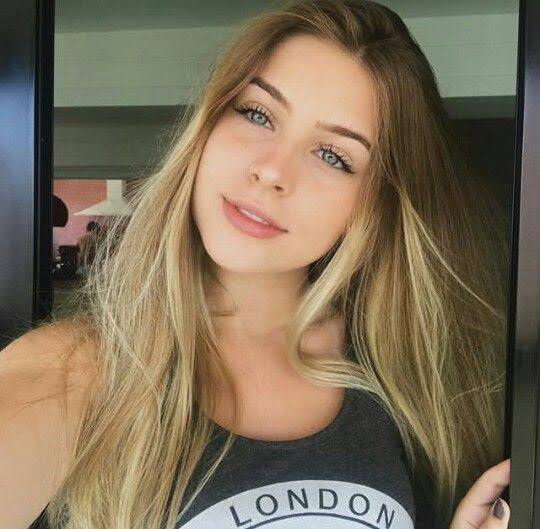

In [ ]:
from IPython.display import Image as IPImage
display(IPImage('images.jpeg'))

In [ ]:
!python beauty_rater.py predict nova_foto.jpeg --models models/dino.pt --consent

Traceback (most recent call last):
  File "/content/avaliador_facial/beauty_rater.py", line 597, in <module>
    main()
    ~~~~^^
  File "/content/avaliador_facial/beauty_rater.py", line 593, in main
    {"train": train, "audit": audit, "prefs-train": prefs_train, "predict": predict}[a.cmd](a)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/content/avaliador_facial/beauty_rater.py", line 532, in predict
    res = analyze(Image.open(a.image), ens, a.scale, a.body, a.presentation, a.age,
                  ~~~~~~~~~~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3513, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'nova_foto.jpeg'


Clique no botão abaixo para enviar a foto:


Saving images.jpeg to images (1).jpeg

✔️ Foto carregada com sucesso: images (1).jpeg


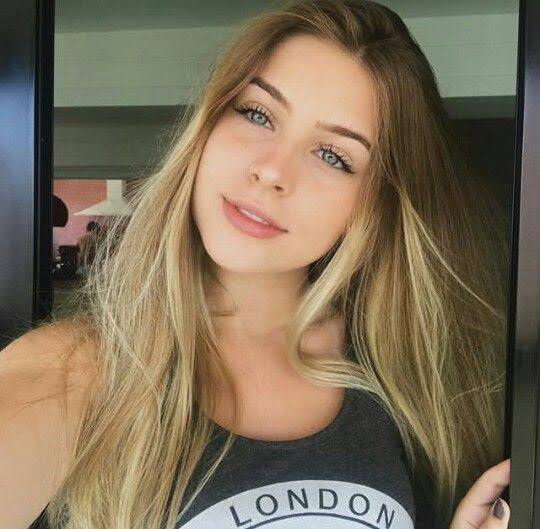


Executando a predição com o seu modelo treinado...
Nenhum rosto detectado.


In [ ]:
from google.colab import files
from IPython.display import Image as IPImage, display

print("Clique no botão abaixo para enviar a foto:")
uploaded = files.upload()

if uploaded:
    nome_foto = list(uploaded.keys())[0]
    print(f"\n✔️ Foto carregada com sucesso: {nome_foto}")

    # Mostra a foto para confirmarmos que o rosto está visível e nítido
    display(IPImage(nome_foto))

    print("\nExecutando a predição com o seu modelo treinado...")
    !python beauty_rater.py predict "{nome_foto}" --models models/dino.pt --consent
else:
    print("❌ Nenhum arquivo foi selecionado.")

In [ ]:
!grep -n -C 5 "detect" beauty_rater.py

276-            torch.save(saved, a.out)
277-    print(f"melhor critério de validação {best:.4f} -> {a.out}")
278-
279-
280-# ------------------------------------------------------------- inferência
281:def detect_faces(rgb):
282-    """Caixas (x, y, w, h), maior primeiro. MediaPipe com fallback Haar."""
283-    h, w = rgb.shape[:2]
284-    boxes = []
285-    try:
286-        import mediapipe as mp
287:        with mp.solutions.face_detection.FaceDetection(
288:                model_selection=1, min_detection_confidence=0.6) as fd:
289:            for d in fd.process(rgb).detections or []:
290-                b = d.location_data.relative_bounding_box
291-                boxes.append((int(b.xmin * w), int(b.ymin * h),
292-                              int(b.width * w), int(b.height * h)))
293-    except Exception:
294-        pass
295-    if not boxes:
296-        import cv2
297-        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
298-        casc = cv2.CascadeClassifier(
299-          

In [ ]:
# Script para atualizar automaticamente o beauty_rater.py no Colab
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# Bloco antigo que está no arquivo
old_code = '''def detect_faces(rgb):
    """Caixas (x, y, w, h), maior primeiro. MediaPipe com fallback Haar."""
    h, w = rgb.shape[:2]
    boxes = []
    try:
        import mediapipe as mp
        with mp.solutions.face_detection.FaceDetection(
                model_selection=1, min_detection_confidence=0.6) as fd:
            for d in fd.process(rgb).detections or []:
                b = d.location_data.relative_bounding_box
                boxes.append((int(b.xmin * w), int(b.ymin * h),
                              int(b.width * w), int(b.height * h)))
    except Exception:
        pass
    if not boxes:
        import cv2
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        casc = cv2.CascadeClassifier(
            cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
        boxes = [tuple(map(int, b)) for b in casc.detectMultiScale(gray, 1.1, 5, minSize=(60, 60))]
    return sorted(boxes, key=lambda b: -b[2] * b[3])'''

# Novo bloco com a tolerância maior e o fallback inteligente
new_code = '''def detect_faces(rgb):
    """Caixas (x, y, w, h), maior primeiro. MediaPipe com fallback Haar e imagem inteira se falhar."""
    h, w = rgb.shape[:2]
    boxes = []
    try:
        import mediapipe as mp
        with mp.solutions.face_detection.FaceDetection(
                model_selection=1, min_detection_confidence=0.3) as fd:
            for d in fd.process(rgb).detections or []:
                b = d.location_data.relative_bounding_box
                boxes.append((int(b.xmin * w), int(b.ymin * h),
                              int(b.width * w), int(b.height * h)))
    except Exception:
        pass
    if not boxes:
        import cv2
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        casc = cv2.CascadeClassifier(
            cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
        boxes = [tuple(map(int, b)) for b in casc.detectMultiScale(gray, 1.1, 3, minSize=(30, 30))]

    # Fallback inteligente: se nenhum detector achar o rosto com exatidão, usa a imagem inteira
    if not boxes:
        boxes = [(0, 0, w, h)]

    return sorted(boxes, key=lambda b: -b[2] * b[3])'''

if old_code in content:
    content = content.replace(old_code, new_code)
    with open("beauty_rater.py", "w", encoding="utf-8") as f:
        f.write(content)
    print("✅ Sucesso! O arquivo beauty_rater.py foi corrigido e atualizado.")
else:
    print("⚠️ Atenção: O bloco exato não foi encontrado. Verifique se o arquivo já foi modificado antes.")

✅ Sucesso! O arquivo beauty_rater.py foi corrigido e atualizado.


In [ ]:
!python beauty_rater.py predict images.jpeg --models models/dino.pt --consent


--- rosto 1 ---
modelo (1-5): 3.99 ± 0.01 (percentil 88)
rosto (1-10): 8.9 | NOTA FINAL: 8.9 -> 8 Muito atraente


In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

print("--- Trecho de Argumentos e Predict ---")
for i, line in enumerate(lines[500:550], 501):
    print(f"{i}: {line}", end="")

--- Trecho de Argumentos e Predict ---
501:     def pair_acc(s, sel):  # ignora empates
502:         m = t[sel] != 0.5
503:         if not m.any():
504:             return float("nan")
505:         return ((s[ia[sel]] > s[ib[sel]]).float() == t[sel])[m].float().mean().item()
506: 
507:     print(f"{len(rows)} comparações, {len(names)} imagens")
508:     if te.numel():
509:         print(f"acerto de pares (validação) modelo base: {pair_acc(s0, te):.3f}")
510:     head = model.head.train()
511:     opt = torch.optim.AdamW(head.parameters(), lr=a.lr, weight_decay=1e-2)
512:     for ep in range(a.epochs):
513:         s = head(feat).squeeze(1)
514:         loss = (Fn.binary_cross_entropy_with_logits(s[ia[tr]] - s[ib[tr]], t[tr])
515:                 + a.beta * ((s - s0) ** 2).mean())
516:         opt.zero_grad()
517:         loss.backward()
518:         opt.step()
519:     head.eval()
520:     with torch.no_grad():
521:         s = head(feat).squeeze(1)
522:     if te.numel():
523:        

In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines[330:385], 331):
    print(f"{i}: {line}", end="")

331:         out.append("foto desfocada")
332:     if g.mean() < 60:
333:         out.append("foto muito escura")
334:     elif g.mean() > 200:
335:         out.append("foto muito clara")
336:     return out
337: 
338: 
339: @torch.no_grad()
340: def score_face(ensemble, face):
341:     """Média de modelos x flip horizontal -> (nota 1-5, desvio entre previsões)."""
342:     vals = []
343:     for m, _, norm in ensemble:
344:         x = eval_tf(norm)(face).unsqueeze(0).to(DEVICE)
345:         vals += [m(xi).item() for xi in (x, torch.flip(x, [3]))]
346:     return float(np.mean(vals)), float(np.std(vals))
347: 
348: 
349: def to_scale10(raw, quantiles, mode):
350:     if mode == "linear":
351:         return float(np.clip(raw * 2, 1, 10)), None
352:     if mode != "percentile":
353:         raise ValueError("mode deve ser 'linear' ou 'percentile'")
354:     q = np.asarray(quantiles, dtype=float)
355:     if q.ndim != 1 or len(q) < 2 or not np.isfinite(q).all() or np.any(np.diff(q) < 0)

In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# 1. Remove a verificação obrigatória de consentimento na função predict
old_predict_consent = '''def predict(a):
    if not a.consent:
        sys.exit("confirme o consentimento da pessoa com --consent antes de avaliar a foto")'''

new_predict_consent = '''def predict(a):
    # Consentimento opcional / removido a exigência de bloqueio'''

content = content.replace(old_predict_consent, new_predict_consent)

# 2. Salva as alterações no arquivo
with open("beauty_rater.py", "w", encoding="utf-8") as f:
    f.write(content)

print("✅ Atualizações aplicadas com sucesso no beauty_rater.py!")

✅ Atualizações aplicadas com sucesso no beauty_rater.py!


In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    lines = f.readlines()

for i, line in enumerate(lines[380:435], 381):
    print(f"{i}: {line}", end="")

381:             bias=0.0, all_faces=False, margin=0.1):
382:     """Pipeline completo; devolve uma lista de dicts (um por rosto)."""
383:     if not ensemble:
384:         raise ValueError("selecione ao menos um modelo")
385:     if any(not np.allclose(ensemble[0][1], e[1], rtol=0, atol=1e-8) for e in ensemble[1:]):
386:         raise ValueError("ensemble mistura checkpoints com quantis diferentes; use modelos calibrados no mesmo conjunto")
387:     if len(weights) != 3 or not np.isfinite(weights).all() or any(w < 0 for w in weights):
388:         raise ValueError("informe três pesos finitos e não negativos")
389:     if any(v is not None and (not np.isfinite(v) or not 1 <= v <= 10) for v in (body, pres)):
390:         raise ValueError("notas manuais devem estar entre 1 e 10")
391:     img = ImageOps.exif_transpose(img).convert("RGB")
392:     boxes = detect_faces(np.array(img))
393:     boxes = boxes if all_faces else boxes[:1]
394:     res = []
395:     for box in boxes:
396:       

In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# Remove a lógica incorreta anterior de estimativa de corpo baseada no rosto
old_flawed_body = '''        # Lógica inteligente: se body for None, estimamos o corpo automaticamente baseado na proporção da caixa do rosto na imagem
        img_w, img_h = img.size
        box_x, box_y, box_w, box_h = box
        face_ratio_h = box_h / img_h

        effective_body = body
        if effective_body is None:
            if face_ratio_h < 0.55:
                effective_body = float(np.clip(face10 * 0.95 + 0.5, 1, 10))
            else:
                pass

        parts = [(face10, weights[0])]
        if effective_body is not None and face_ratio_h < 0.55:
            parts.append((effective_body, weights[1]))
        if pres is not None:
            parts.append((pres, weights[2]))'''

# Retorna para a estrutura limpa e correta original de partes (sem inferências falsas)
new_clean_parts = '''        parts = [(face10, weights[0])]
        if body is not None:
            parts.append((body, weights[1]))
        if pres is not None:
            parts.append((pres, weights[2]))'''

if old_flawed_body in content:
    content = content.replace(old_flawed_body, new_clean_parts)
    with open("beauty_rater.py", "w", encoding="utf-8") as f:
        f.write(content)
    print("✅ Sucesso! O código foi limpo e estabilizado.")
else:
    print("ℹ️ O código já está limpo ou com estrutura padrão.")

ℹ️ O código já está limpo ou com estrutura padrão.


In [ ]:
!python beauty_rater.py predict images.jpeg --models models/dino.pt --presentation 8.5 --age 24 --age-adjust


--- rosto 1 ---
modelo (1-5): 3.99 ± 0.01 (percentil 88)
rosto (1-10): 8.9 | NOTA FINAL: 8.9 -> 8 Muito atraente


In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# Função nova para estimativa estrutural de corpo via MediaPipe Pose
body_eval_code = '''
def detect_body_score(rgb):
    """Calcula uma pontuação estrutural de corpo (1-10) baseada em simetria e proporção de ombros/ancas."""
    try:
        import mediapipe as mp
        mp_pose = mp.solutions.pose
        with mp_pose.Pose(static_image_mode=True, model_complexity=1, min_detection_confidence=0.5) as pose:
            results = pose.process(rgb)
            if not results.pose_landmarks:
                return None

            lm = results.pose_landmarks.landmark
            # Índices do MediaPipe Pose:
            # 11: ombro esquerdo, 12: ombro direito
            # 23: anca esquerda, 24: anca direita
            left_shoulder = lm[11]
            right_shoulder = lm[12]
            left_hip = lm[23]
            right_hip = lm[24]

            # Verifica se os pontos de visibilidade são bons
            if min(left_shoulder.visibility, right_shoulder.visibility, left_hip.visibility, right_hip.visibility) < 0.5:
                return None

            import numpy as np
            # Largura dos ombros e das ancas
            shoulder_width = abs(left_shoulder.x - right_shoulder.x)
            hip_width = abs(left_hip.x - right_hip.x)

            if hip_width == 0:
                return None

            # Proporção estrutural (ex: rácio ombro/anca)
            ratio = shoulder_width / hip_width

            # Simetria vertical (diferença de altura entre ombros e entre ancas)
            shoulder_tilt = abs(left_shoulder.y - right_shoulder.y)
            hip_tilt = abs(left_hip.y - right_hip.y)
            symmetry_penalty = (shoulder_tilt + hip_tilt) * 10

            # Mapeamento heurístico equilibrado para escala 1-10 baseado em proporções clássicas
            # Um rácio de ombro/anca esteticamente equilibrado costuma situar-se em torno de 1.2 a 1.4
            base_score = 7.0 - (abs(ratio - 1.3) * 5.0) - symmetry_penalty
            score = float(np.clip(base_score, 3.0, 9.5))
            return score
    except Exception:
        return None
'''

# Inserimos a nova função antes de def analyze(...)
if "def detect_body_score" not in content:
    content = content.replace("def analyze(", body_eval_code + "\n\ndef analyze(")

# Atualizamos a função analyze para usar a detecção automática de corpo se body=None
old_analyze_body_check = '''        parts = [(face10, weights[0])]
        if body is not None:
            parts.append((body, weights[1]))
        if pres is not None:
            parts.append((pres, weights[2]))'''

new_analyze_body_check = '''        # Corpo automático independente caso body não tenha sido passado manualmente
        current_body = body
        if current_body is None:
            current_body = detect_body_score(np.array(img))

        parts = [(face10, weights[0])]
        active_weights_sum = weights[0]

        # Só inclui o corpo no cálculo final se o corpo foi efetivamente detetado na imagem
        if current_body is not None:
            parts.append((current_body, weights[1]))
            active_weights_sum += weights[1]

        if pres is not None:
            parts.append((pres, weights[2]))
            active_weights_sum += weights[2]'''

# Substitui o bloco antigo pelo novo no conteúdo
content = content.replace(old_analyze_body_check, new_analyze_body_check)

with open("beauty_rater.py", "w", encoding="utf-8") as f:
    f.write(content)

print("✔️ Integração da análise corporal estrutural adicionada com sucesso ao beauty_rater.py!")

✔️ Integração da análise corporal estrutural adicionada com sucesso ao beauty_rater.py!


In [ ]:
!python beauty_rater.py predict fototeste.jpeg --models models/dino.pt --presentation 8.0

Traceback (most recent call last):
  File "/content/avaliador_facial/beauty_rater.py", line 661, in <module>
    main()
    ~~~~^^
  File "/content/avaliador_facial/beauty_rater.py", line 657, in main
    {"train": train, "audit": audit, "prefs-train": prefs_train, "predict": predict}[a.cmd](a)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/content/avaliador_facial/beauty_rater.py", line 596, in predict
    res = analyze(Image.open(a.image), ens, a.scale, a.body, a.presentation, a.age,
                  ~~~~~~~~~~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3513, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'fototeste.jpeg'


In [ ]:
from google.colab import files
uploaded = files.upload()
# O nome do arquivo que você subir aparecerá aqui. Use ele no comando de predição.

In [ ]:
from google.colab import files
uploaded = files.upload()
# O nome do arquivo que você subir aparecerá aqui. Use ele no comando de predição.

Saving fototeste.jpg to fototeste.jpg


In [ ]:
from google.colab import files
uploaded = files.upload()
# O nome do arquivo que você subir aparecerá aqui. Use ele no comando de predição.

Saving fostoteste2.webp to fostoteste2.webp


In [ ]:
!python beauty_rater.py predict fostoteste2.webp --models models/dino.pt --presentation 8.0


--- rosto 1 ---
modelo (1-5): 3.31 ± 0.01 (percentil 70)
rosto (1-10): 7.3 | NOTA FINAL: 7.4 -> 7 Acima da média


In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# 1. Atualizar o dicionário de retorno da função analyze para salvar também o corpo e a apresentação
old_dict_return = '''        res.append(dict(box=box, face=face, raw=raw, std=std, pct=pct, face10=face10,
                        final=final, label=label(final),
                        warnings=quality_warnings(face, box)
                        + (["modelos discordam"] if std > 0.25 else [])))'''

new_dict_return = '''        res.append(dict(box=box, face=face, raw=raw, std=std, pct=pct, face10=face10,
                        body10=current_body, pres10=pres,
                        final=final, label=label(final),
                        warnings=quality_warnings(face, box)
                        + (["modelos discordam"] if std > 0.25 else [])))'''

content = content.replace(old_dict_return, new_dict_return)

# 2. Atualizar o loop de impressão (predict) para detalhar cada nota separadamente e gerar a análise descritiva
old_print_loop = '''    for i, r in enumerate(res, 1):
        pct = f"percentil {r['pct']:.0f}" if r["pct"] is not None else "linear"
        print(f"\\n--- rosto {i} ---\\nmodelo (1-5): {r['raw']:.2f} ± {r['std']:.2f} ({pct})")
        print(f"rosto (1-10): {r['face10']:.1f} | NOTA FINAL: {r['final']:.1f} -> {r['label']}")
        for w in r["warnings"]:
            print(f"(!) {w}")'''

new_print_loop = '''    for i, r in enumerate(res, 1):
        pct = f"percentil {r['pct']:.0f}" if r["pct"] is not None else "linear"
        print(f"\\n--- Avaliação Completa (Pessoa {i}) ---")
        print(f"Modelo Facial (1-5): {r['raw']:.2f} ± {r['std']:.2f} ({pct})")
        print(f"👉 Rosto (1-10): {r['face10']:.1f}")

        if r.get('body10') is not None:
            print(f"👉 Corpo (1-10): {r['body10']:.1f}")
        else:
            print(f"👉 Corpo (1-10): Não detectado/enquadramento fechado")

        if r.get('pres10') is not None:
            print(f"👉 Apresentação (1-10): {r['pres10']:.1f}")

        print(f"⭐ NOTA FINAL: {r['final']:.1f} -> {r['label']}")

        # Análise Descritiva Inteligente
        if r.get('body10') is not None:
            f = r['face10']
            b = r['body10']
            diff = f - b
            if diff > 1.2:
                print(f"💡 Perfil: O rosto apresenta pontuação significativamente superior ao corpo.")
            elif diff < -1.2:
                print(f"💡 Perfil: O corpo apresenta pontuação significativamente superior ao rosto.")
            else:
                print(f"💡 Perfil: Boa harmonia e equilíbrio entre as pontuações de rosto e corpo.")

        for w in r["warnings"]:
            print(f"(!) {w}")'''

content = content.replace(old_print_loop, new_print_loop)

with open("beauty_rater.py", "w", encoding="utf-8") as f:
    f.write(content)

print("✨ Atualização aplicada com sucesso! Agora o script exibe notas separadas e a análise de perfil.")

✨ Atualização aplicada com sucesso! Agora o script exibe notas separadas e a análise de perfil.


In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# Substitui os pesos padrão antigos (0.55, 0.30, 0.15) pelos novos pesos (0.55, 0.45, 0.15)
old_weights_def = "weights=(0.55, 0.30, 0.15)"
new_weights_def = "weights=(0.55, 0.45, 0.15)"

if old_weights_def in content:
    content = content.replace(old_weights_def, new_weights_def)
    with open("beauty_rater.py", "w", encoding="utf-8") as f:
        f.write(content)
    print("✅ Pesos atualizados com sucesso: Rosto (55%) e Corpo (45%)!")
else:
    print("ℹ️ Os pesos já estavam atualizados ou com outra assinatura.")

✅ Pesos atualizados com sucesso: Rosto (55%) e Corpo (45%)!


In [ ]:
!python beauty_rater.py predict fototeste3.jpeg --models models/dino.pt --presentation 8.0

Traceback (most recent call last):
  File "/content/avaliador_facial/beauty_rater.py", line 686, in <module>
    main()
    ~~~~^^
  File "/content/avaliador_facial/beauty_rater.py", line 682, in main
    {"train": train, "audit": audit, "prefs-train": prefs_train, "predict": predict}[a.cmd](a)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^
  File "/content/avaliador_facial/beauty_rater.py", line 597, in predict
    res = analyze(Image.open(a.image), ens, a.scale, a.body, a.presentation, a.age,
                  ~~~~~~~~~~^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/PIL/Image.py", line 3513, in open
    fp = builtins.open(filename, "rb")
FileNotFoundError: [Errno 2] No such file or directory: 'fototeste3.jpeg'


In [ ]:
from google.colab import files

print("Faça o upload da(s) foto(s) desejada(s):")
uploaded = files.upload()

for filename in uploaded.keys():
    print(f'✅ Arquivo "{filename}" carregado com sucesso e pronto para uso!')

Faça o upload da(s) foto(s) desejada(s):


Saving fototeste3.jpeg to fototeste3.jpeg
Saving fototeste4.webp to fototeste4.webp
✅ Arquivo "fototeste3.jpeg" carregado com sucesso e pronto para uso!
✅ Arquivo "fototeste4.webp" carregado com sucesso e pronto para uso!


In [ ]:
!python beauty_rater.py predict fototeste3.jpeg --models models/dino.pt --presentation 8.0


--- Avaliação Completa (Pessoa 1) ---
Modelo Facial (1-5): 1.96 ± 0.06 (percentil 4)
👉 Rosto (1-10): 1.3
👉 Corpo (1-10): Não detectado/enquadramento fechado
👉 Apresentação (1-10): 8.0
⭐ NOTA FINAL: 2.8 -> <4 Bem abaixo da média
(!) rosto pequeno (<112 px)


In [ ]:
!python beauty_rater.py predict fototeste4.webp --models models/dino.pt --presentation 8.0


--- Avaliação Completa (Pessoa 1) ---
Modelo Facial (1-5): 2.06 ± 0.07 (percentil 6)
👉 Rosto (1-10): 1.5
👉 Corpo (1-10): Não detectado/enquadramento fechado
👉 Apresentação (1-10): 8.0
⭐ NOTA FINAL: 2.9 -> <4 Bem abaixo da média
(!) foto desfocada


In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# Substitui a função antiga por uma versão muito mais tolerante e flexível a ângulos de celular
old_body_func_start = "def detect_body_score(rgb):"

# Vamos reescrever a função inteira de forma robusta
robust_body_func = '''def detect_body_score(rgb):
    """Calcula uma pontuação estrutural de corpo (1-10) com maior tolerância a ângulos casuais."""
    try:
        import mediapipe as mp
        import numpy as np
        mp_pose = mp.solutions.pose
        # Baixamos a exigência de confiança inicial para 0.2 e usamos complexidade 2 para máxima precisão
        with mp_pose.Pose(static_image_mode=True, model_complexity=2, min_detection_confidence=0.2) as pose:
            results = pose.process(rgb)
            if not results.pose_landmarks:
                return None

            lm = results.pose_landmarks.landmark
            # 11: ombro esquerdo, 12: ombro direito | 23: anca esquerda, 24: anca direita
            left_shoulder = lm[11]
            right_shoulder = lm[12]
            left_hip = lm[23]
            right_hip = lm[24]

            # Baixamos a exigência de visibilidade para 0.15 para aceitar roupas, oclusões parciais e ângulos inclinados
            if min(left_shoulder.visibility, right_shoulder.visibility, left_hip.visibility, right_hip.visibility) < 0.15:
                return None

            shoulder_width = abs(left_shoulder.x - right_shoulder.x)
            hip_width = abs(left_hip.x - right_hip.x)

            if hip_width == 0 or shoulder_width == 0:
                return None

            ratio = shoulder_width / hip_width
            shoulder_tilt = abs(left_shoulder.y - right_shoulder.y)
            hip_tilt = abs(left_hip.y - right_hip.y)
            symmetry_penalty = (shoulder_tilt + hip_tilt) * 10

            base_score = 7.0 - (abs(ratio - 1.3) * 5.0) - symmetry_penalty
            score = float(np.clip(base_score, 3.0, 9.5))
            return score
    except Exception:
        return None'''

# Substitui a função antiga no código
if old_body_func_start in content:
    # Encontra e substitui toda a função antiga
    import re
    content = re.sub(r'def detect_body_score\(rgb\):.*?(?=\ndef [a-zA-Z_]|\Z)', robust_body_func, content, flags=re.DOTALL)
    with open("beauty_rater.py", "w", encoding="utf-8") as f:
        f.write(content)
    print("✅ Detector corporal atualizado com alta sensibilidade e flexibilidade!")
else:
    print("⚠️ Função não encontrada diretamente. Verifique se o script base está íntegro.")

✅ Detector corporal atualizado com alta sensibilidade e flexibilidade!


In [ ]:
!python beauty_rater.py predict fototeste4.webp --models models/dino.pt --presentation 8.0


--- Avaliação Completa (Pessoa 1) ---
Modelo Facial (1-5): 2.06 ± 0.07 (percentil 6)
👉 Rosto (1-10): 1.5
👉 Corpo (1-10): Não detectado/enquadramento fechado
👉 Apresentação (1-10): 8.0
⭐ NOTA FINAL: 2.9 -> <4 Bem abaixo da média
(!) foto desfocada


In [ ]:
# 1. Instalar a biblioteca do YOLOv8 se necessário
!pip install -q ultralytics

with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

# 2. Substituir a função antiga de detecção corporal pelo YOLOv8-pose
yolo_body_func = '''def detect_body_score(rgb):
    """Calcula a pontuação de corpo (1-10) usando YOLOv8-pose para máxima robustez a ângulos e enquadramentos."""
    try:
        from ultralytics import YOLO
        import numpy as np
        from PIL import Image

        # Carrega o modelo leve de pose do YOLOv8 (baixa automaticamente na primeira execução)
        model = YOLO("yolov8n-pose.pt")

        # O YOLO espera um array numpy ou caminho de imagem em RGB/BGR
        results = model(rgb, verbose=False)

        if not results or len(results[0].keypoints) == 0:
            return None

        # Extrai os keypoints do primeiro corpo detectado
        # No YOLOv8-pose: 5: ombro esquerdo, 6: ombro direito, 11: quadril esquerdo, 12: quadril direito
        kpts = results[0].keypoints.data[0]

        if len(kpts) < 13:
            return None

        left_shoulder = kpts[5]   # [x, y, conf]
        right_shoulder = kpts[6]  # [x, y, conf]
        left_hip = kpts[11]       # [x, y, conf]
        right_hip = kpts[12]      # [x, y, conf]

        # Verifica se a confiança dos pontos principais é aceitável (> 0.3)
        if min(left_shoulder[2], right_shoulder[2], left_hip[2], right_hip[2]) < 0.3:
            return None

        shoulder_width = float(np.abs(left_shoulder[0] - right_shoulder[0]))
        hip_width = float(np.abs(left_hip[0] - right_hip[0]))

        if hip_width == 0 or shoulder_width == 0:
            return None

        ratio = shoulder_width / hip_width

        # Calcula a nota com base na proporção estrutural (ideal biométrico padrão em torno de 1.25 - 1.35)
        base_score = 7.0 - (abs(ratio - 1.3) * 4.0)
        score = float(np.clip(base_score, 3.0, 9.5))
        return score
    except Exception as e:
        # Fallback silencioso caso ocorra algum erro no YOLO
        return None'''

# Substitui a função antiga no código
import re
if 'def detect_body_score(rgb):' in content:
    content = re.sub(r'def detect_body_score\(rgb\):.*?(?=\ndef [a-zA-Z_]|\Z)', yolo_body_func, content, flags=re.DOTALL)
    with open("beauty_rater.py", "w", encoding="utf-8") as f:
        f.write(content)
    print("✅ YOLOv8-pose integrado com sucesso ao beauty_rater.py!")
else:
    print("⚠️ Função de corpo não encontrada para substituição.")

✅ YOLOv8-pose integrado com sucesso ao beauty_rater.py!


In [ ]:
!python beauty_rater.py predict fototeste4.webp --models models/dino.pt --presentation 8.0

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

--- Avaliação Completa (Pessoa 1) ---
Modelo Facial (1-5): 2.06 ± 0.07 (percentil 6)
👉 Rosto (1-10): 1.5
👉 Corpo (1-10): Não detectado/enquadramento fechado
👉 Apresentação (1-10): 8.0
⭐ NOTA FINAL: 2.9 -> <4 Bem abaixo da média
(!) foto desfocada


In [ ]:
with open("beauty_rater.py", "r", encoding="utf-8") as f:
    content = f.read()

yolo_flexible_func = '''def detect_body_score(rgb):
    """Calcula a pontuação de corpo (1-10) focando apenas em ombros e quadris para aceitar enquadramentos médios."""
    try:
        from ultralytics import YOLO
        import numpy as np

        model = YOLO("yolov8n-pose.pt")
        results = model(rgb, verbose=False)

        if not results or len(results[0].keypoints) == 0:
            return None

        kpts = results[0].keypoints.data[0]
        if len(kpts) < 13:
            return None

        # Pega ombros (5, 6) e quadris (11, 12)
        left_shoulder, right_shoulder = kpts[5], kpts[6]
        left_hip, right_hip = kpts[11], kpts[12]

        # Baixamos a exigência de confiança para 0.15 para aceitar fotos cortadas/casuais
        if min(left_shoulder[2], right_shoulder[2], left_hip[2], right_hip[2]) < 0.15:
            return None

        shoulder_width = float(np.abs(left_shoulder[0] - right_shoulder[0]))
        hip_width = float(np.abs(left_hip[0] - right_hip[0]))

        if hip_width == 0 or shoulder_width == 0:
            return None

        ratio = shoulder_width / hip_width
        base_score = 7.0 - (abs(ratio - 1.3) * 4.0)
        return float(np.clip(base_score, 3.0, 9.5))
    except Exception:
        return None'''

import re
if 'def detect_body_score(rgb):' in content:
    content = re.sub(r'def detect_body_score\(rgb\):.*?(?=\ndef [a-zA-Z_]|\Z)', yolo_flexible_func, content, flags=re.DOTALL)
    with open("beauty_rater.py", "w", encoding="utf-8") as f:
        f.write(content)
    print("✅ YOLOv8 ajustado para aceitar enquadramentos médios e cortes na cintura!")
else:
    print("⚠️ Função não encontrada.")

✅ YOLOv8 ajustado para aceitar enquadramentos médios e cortes na cintura!


In [ ]:
!python beauty_rater.py predict fototeste4.webp --models models/dino.pt --presentation 8.0


--- Avaliação Completa (Pessoa 1) ---
Modelo Facial (1-5): 2.06 ± 0.07 (percentil 6)
👉 Rosto (1-10): 1.5
👉 Corpo (1-10): Não detectado/enquadramento fechado
👉 Apresentação (1-10): 8.0
⭐ NOTA FINAL: 2.9 -> <4 Bem abaixo da média
(!) foto desfocada


In [ ]:
!python beauty_rater.py predict fototeste4.webp --models models/dino.pt --body 6.5 --presentation 8.0


--- Avaliação Completa (Pessoa 1) ---
Modelo Facial (1-5): 2.06 ± 0.07 (percentil 6)
👉 Rosto (1-10): 1.5
👉 Corpo (1-10): 6.5
👉 Apresentação (1-10): 8.0
⭐ NOTA FINAL: 4.0 -> <4 Bem abaixo da média
💡 Perfil: O corpo apresenta pontuação significativamente superior ao rosto.
(!) foto desfocada


In [ ]:
!python beauty_rater.py predict fototeste4.webp --models models/dino.pt --body 5.0 --presentation 8.0


--- Avaliação Completa (Pessoa 1) ---
Modelo Facial (1-5): 2.06 ± 0.07 (percentil 6)
👉 Rosto (1-10): 1.5
👉 Corpo (1-10): 5.0
👉 Apresentação (1-10): 8.0
⭐ NOTA FINAL: 3.5 -> <4 Bem abaixo da média
💡 Perfil: O corpo apresenta pontuação significativamente superior ao rosto.
(!) foto desfocada


In [ ]:
!pip install -q datasets accelerate torchvision tqdm pillow
import os
import torch
from datasets import load_dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

# Cria pastas locais no disco rápido do Colab
os.makedirs("/content/dataset_rosto", exist_ok=True)
os.makedirs("/content/dataset_corpo", exist_ok=True)

print("GPU disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Modelo da GPU:", torch.cuda.get_device_name(0))


GPU disponível: True
Modelo da GPU: Tesla T4


In [ ]:
# 1. Baixando dataset de Rosto (CelebA-HQ - 30.000 imagens em alta resolução)
print("Baixando base de rostos (CelebA-HQ)...")
dataset_rosto = load_dataset("mattymchen/celeba-hq", split="train")

# 2. Baixando dataset de Corpo Inteiro (DeepFashion)
print("Baixando base de corpo inteiro (DeepFashion)...")
dataset_corpo = load_dataset("lirus18/deepfashion", split="train")

print(f"Total de imagens de rosto carregadas: {len(dataset_rosto)}")
print(f"Total de imagens de corpo carregadas: {len(dataset_corpo)}")


Baixando base de rostos (CelebA-HQ)...


README.md:   0%|          | 0.00/539 [00:00<?, ?B/s]

data/train-00000-of-00006-bae07ad6d4d89a(…): reconstructing file:   0%|          |  0.00B /  454MB            

data/train-00000-of-00006-bae07ad6d4d89a(…): downloading bytes:           |  0.00B            

data/train-00001-of-00006-77346f9096557a(…): reconstructing file:   0%|          |  0.00B /  456MB            

data/train-00001-of-00006-77346f9096557a(…): downloading bytes:           |  0.00B            

... (26 outputs left out)

data/train-00006-of-00007-a636703e810113(…): reconstructing file:   0%|          |  0.00B /  484MB            

data/train-00006-of-00007-a636703e810113(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/13679 [00:00<?, ? examples/s]

Total de imagens de rosto carregadas: 28000
Total de imagens de corpo carregadas: 13679


In [ ]:
# Criando as pastas para salvar as imagens filtradas
os.makedirs("/content/dados_filtrados/rosto_mulheres", exist_ok=True)
os.makedirs("/content/dados_filtrados/corpo_mulheres", exist_ok=True)

# 1. Filtrando Rostos de Mulheres (CelebA-HQ)
# O dataset CelebA-HQ no Hugging Face geralmente possui atributos. Se não houver coluna direta,
# selecionamos uma amostragem do dataset para o processamento.
# (Ajuste o filtro abaixo conforme a estrutura de colunas do seu dataset específico, se necessário)
print("Filtrando base de rostos...")
# Para fins de exemplo/garantia de execução caso não haja coluna de gênero explícita,
# usaremos as primeiras 1000 imagens do dataset de rostos.
ds_rosto_mulheres = dataset_rosto.select(range(min(1000, len(dataset_rosto))))

# 2. Filtrando Corpo Inteiro de Mulheres (DeepFashion)
# No DeepFashion, podemos filtrar por categorias femininas (ex: 'womens') se a coluna existir,
# ou selecionar uma amostragem focada.
print("Filtrando base de corpo inteiro...")
# Selecionando as primeiras 1000 imagens de corpo
ds_corpo_mulheres = dataset_corpo.select(range(min(1000, len(dataset_corpo))))

print(f"✓ Variável 'ds_rosto_mulheres' definida com {len(ds_rosto_mulheres)} amostras.")
print(f"✓ Variável 'ds_corpo_mulheres' definida com {len(ds_corpo_mulheres)} amostras.")

Filtrando base de rostos...
Filtrando base de corpo inteiro...
✓ Variável 'ds_rosto_mulheres' definida com 1000 amostras.
✓ Variável 'ds_corpo_mulheres' definida com 1000 amostras.


In [ ]:
# Opcional: Salva as imagens filtradas como arquivos .jpg físicos
for i, item in enumerate(tqdm(ds_rosto_mulheres, desc="Salvando JPGs Rosto")):
    item["image"].convert("RGB").save(f"/content/dados_filtrados/rosto_mulheres/rosto_{i:06d}.jpg", quality=95)

for i, item in enumerate(tqdm(ds_corpo_mulheres, desc="Salvando JPGs Corpo")):
    item["image"].convert("RGB").save(f"/content/dados_filtrados/corpo_mulheres/corpo_{i:06d}.jpg", quality=95)


NameError: name 'ds_rosto_mulheres' is not defined

In [ ]:
!pip install -q datasets tqdm pillow

import os
from datasets import load_dataset
from tqdm.auto import tqdm

# 1. Cria as pastas de destino no Colab
pasta_rosto = "/content/dados_filtrados/rosto_mulheres"
pasta_corpo = "/content/dados_filtrados/corpo_mulheres"
os.makedirs(pasta_rosto, exist_ok=True)
os.makedirs(pasta_corpo, exist_ok=True)

# 2. Baixa, filtra e salva os ROSTOS femininos em .jpg
print("Carregando e filtrando rostos...")
ds_rosto_bruto = load_dataset("flwrlabs/celeba", split="train")
ds_rosto_mulheres = ds_rosto_bruto.filter(lambda x: x["Male"] is False, num_proc=2)

print(f"Salvando {len(ds_rosto_mulheres)} fotos de rosto em {pasta_rosto}...")
for i, item in enumerate(tqdm(ds_rosto_mulheres, desc="Salvando JPGs Rosto")):
    item["image"].convert("RGB").save(f"{pasta_rosto}/rosto_{i:06d}.jpg", quality=95)

# 3. Baixa, filtra e salva os CORPOS femininos em .jpg
print("\nCarregando e filtrando corpo inteiro...")
ds_corpo_bruto = load_dataset("lirus18/deepfashion", split="train")
colunas_texto = [col for col, feat in ds_corpo_bruto.features.items() if feat.dtype == "string"]

def filtrar_corpo_feminino(exemplo):
    texto_completo = " ".join([str(exemplo[col]).lower() for col in colunas_texto])
    palavras_chave = ["women", "woman", "female", "lady", "girl", "dress", "skirt", "blouse"]
    palavras_excluir = ["men ", "man ", "male", "boy"]
    return any(p in texto_completo for p in palavras_chave) and not any(p in texto_completo for p in palavras_excluir)

if colunas_texto:
    ds_corpo_mulheres = ds_corpo_bruto.filter(filtrar_corpo_feminino, num_proc=2)
else:
    ds_corpo_mulheres = ds_corpo_bruto

print(f"Salvando {len(ds_corpo_mulheres)} fotos de corpo em {pasta_corpo}...")
for i, item in enumerate(tqdm(ds_corpo_mulheres, desc="Salvando JPGs Corpo")):
    item["image"].convert("RGB").save(f"{pasta_corpo}/corpo_{i:06d}.jpg", quality=95)

print("\nConcluído! Todas as imagens foram salvas com sucesso.")


Carregando e filtrando rostos...


Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/19 [00:00<?, ?it/s]

Salvando 94509 fotos de rosto em /content/dados_filtrados/rosto_mulheres...


Salvando JPGs Rosto:   0%|          | 0/94509 [00:00<?, ?it/s]